## Clean Data Gen

- time series
- hourly flows from 2022 to 2024 
- per detector (should be six along VCI)

In [3]:
## ==== Unzipping datasets ====

import zipfile

In [5]:
with zipfile.ZipFile("../../VCI_DT4MOB.zip") as zip_ref:
    zip_ref.extractall()
    print("Extracted files:")
    for file in zip_ref.namelist():
        print(file)

Extracted files:
05_VCI_DT4MOB/
05_VCI_DT4MOB/Diario_2022/
05_VCI_DT4MOB/Diario_2022/EP_2022_01.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_02.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_03.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_04.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_05.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_06.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_07.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_08.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_09.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_10.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_11.xlsx
05_VCI_DT4MOB/Diario_2022/EP_2022_12.xlsx
05_VCI_DT4MOB/Diario_2023/
05_VCI_DT4MOB/Diario_2023/EP_2023_01.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_02.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_03.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_04.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_05.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_06.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_07.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_08.xlsx
05_VCI_DT4MOB/Diario_2023/EP_2023_09.xlsx
05_VCI_DT4MOB/Diario_2023/EP_202

In [2]:
## ==== Loading monthly datasets ====
import pandas as pd 
import unicodedata
import datetime
import os 


In [8]:
# one xlsx per month ("EP_2022_01.xlsx" for month 1 of 2022), each containing hourly data over that month, different folders for each year ("Diario_2022", "Diario_2023", "Diario_2024")
# keep one dataset per sublanco and sentido, with hourly flow (ligeiros + pesados or classea+classeb+classec+classed)

## --- helper functions ---
def normalize(col):
    col = col.strip()
    col = unicodedata.normalize('NFKD', col)
    col = col.encode('ascii', 'ignore').decode('utf-8')
    return col.lower()

def compute_flows(row):
    # ligeiros + pesados
    if pd.notna(row.get('ligeiros')) or pd.notna(row.get('pesados')):
        flow = row.get('ligeiros', 0) + row.get('pesados', 0)
    # classea + classeb + classec + classed
    else:
        flow = sum([row.get(c,0) for c in ['classea','classeb','classec','classed']])
    return flow

# columns to load
needed_cols = {
    "sublanco","ano","mes","dia","hora","sentido",
    "classea","classeb","classec","classed",
    "ligeiros","pesados"
}

# sublancos to load
keep_sublancos = [
                'A3 - Paranhos',
                'Antas - A3',
                'Campo Alegre - Boavista',
                'Freixo(A43) - Mercado Abastecedor',
                'Mercado Abastecedor - Antas',
                'N14/Circunvalação - Boavista',
                'Paranhos - Amial',
            ]

# --- main loop ---

all_data = []
sublacos_in_files = set()
for year in [2022, 2023, 2024]:
    for month in range(1, 13):
        file_path = f"05_VCI_DT4MOB/Diario_{year}/EP_{year}_{month:02d}.xlsx"
        
        if not os.path.exists(file_path):
            print(f"File not found: {file_path}")
            continue

        df = pd.read_excel(
            file_path,
            usecols=lambda x: normalize(x) in needed_cols
            )
        
        df.columns = [normalize(c) for c in df.columns]
        
        # list all sublancos and sentidos in this file
        sublacos_in_files.update(df['sublanco'].unique())
        # select sublancos
        df = df[df['sublanco'].isin(keep_sublancos)]

        df["flows"] = df.apply(compute_flows, axis=1)

        df['timestamp'] = pd.to_datetime({
            'year': df['ano'],
            'month': df['mes'],
            'day': df['dia'],
            'hour': df['hora']
        })

        # Append to list
        all_data.append(df[['sublanco','sentido','timestamp','flows']])
        print(f"Processed {file_path} ({len(df)} rows)")

Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_01.xlsx (8929 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_02.xlsx (9408 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_03.xlsx (10416 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_04.xlsx (8641 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_05.xlsx (8929 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_06.xlsx (8641 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_07.xlsx (7442 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_08.xlsx (7442 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_09.xlsx (7202 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_10.xlsx (8929 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_11.xlsx (8641 rows)
Processed 05_VCI_DT4MOB/Diario_2022/EP_2022_12.xlsx (10416 rows)
Processed 05_VCI_DT4MOB/Diario_2023/EP_2023_01.xlsx (7442 rows)
Processed 05_VCI_DT4MOB/Diario_2023/EP_2023_02.xlsx (9408 rows)
Processed 05_VCI_DT4MOB/Diario_2023/EP_2023_03.xlsx (10416 rows)
Processed 05_VCI_DT4MOB/Diario_2023/E

In [4]:
sublacos_in_files

{'A3 - Paranhos',
 'A44/A29 - Canidelo',
 'Antas - A3',
 'Av. Da República - Gaia (centro)',
 'Avintes(N222) - Oliveira do Douro(A44)',
 'Boavista - Rotunda AEP',
 'Campo Alegre - Boavista',
 'Canelas - Avintes(N222)',
 'Canidelo - Afurada',
 'Carvalhos - Canelas',
 'Coimbrões - Av. Da República',
 'Freixo(A43) - Mercado Abastecedor',
 'Gaia (centro) - Pte. Freixo (A20)',
 'Mercado Abastecedor - Antas',
 'N14/Circunvalação - Boavista',
 'Nó RALIS - Nó IC17/CRIL (Sacavém)',
 'Paranhos - Amial',
 'Rotunda AEP - Senhora da Hora',
 'Santo Ovideo - A44/A29'}

In [9]:
# dataset
full_data = pd.concat(all_data, ignore_index=True)

In [12]:
sublancos_in_data = full_data['sublanco'].unique()
print(len(sublancos_in_data))
print(sublancos_in_data)

7
['A3 - Paranhos' 'Antas - A3' 'Freixo(A43) - Mercado Abastecedor'
 'Mercado Abastecedor - Antas' 'N14/Circunvalação - Boavista'
 'Paranhos - Amial' 'Campo Alegre - Boavista']


In [13]:
full_data

,sublanco,sentido,timestamp,flows
0,A3 - Paranhos,1.0,2022-01-01 00:00:00,1278.0
1,A3 - Paranhos,-1.0,2022-01-01 00:00:00,1278.0
2,A3 - Paranhos,1.0,2022-01-01 01:00:00,1372.0
3,A3 - Paranhos,-1.0,2022-01-01 01:00:00,1372.0
4,A3 - Paranhos,1.0,2022-01-01 02:00:00,778.0
...,...,...,...,...
319804,Paranhos - Amial,-1.0,2024-12-31 19:00:00,3823.0
319805,Paranhos - Amial,-1.0,2024-12-31 20:00:00,2136.0
319806,Paranhos - Amial,-1.0,2024-12-31 21:00:00,1076.0
319807,Paranhos - Amial,-1.0,2024-12-31 22:00:00,1307.0


In [ ]:
# how many sublancos/sentidos
print(full_data.groupby(['sublanco','sentido']).size())

sublanco                           sentido
A3 - Paranhos                      -1.0       26304
                                    1.0       26304
Antas - A3                         -1.0       22656
                                    1.0       22656
Campo Alegre - Boavista            -1.0       25560
                                    1.0       25560
Freixo(A43) - Mercado Abastecedor  -1.0       25560
                                    1.0       25560
Mercado Abastecedor - Antas        -1.0       26304
                                    1.0       26304
N14/Circunvalação - Boavista       -1.0       13824
                                    1.0       13824
Paranhos - Amial                   -1.0       19680
                                    1.0       19680
dtype: int64


In [21]:
# create csv datasets per sublanco and sentido, with columns "timestamp" and "flows"
output_dir = "hourly_flows_by_detector"
os.makedirs(output_dir, exist_ok=True)

for (sublanco, sentido), group in full_data.groupby(['sublanco','sentido']):

    filename = f"{sublanco.replace(' ','_').replace('/','_')}_{str(sentido)}.csv"
    filepath = os.path.join(output_dir, filename)
    group.to_csv(filepath, sep=';', index=False)
    print(f"Exported {filepath} ({len(group)} rows)")


Exported hourly_flows_by_detector/A3_-_Paranhos_-1.0.csv (26304 rows)
Exported hourly_flows_by_detector/A3_-_Paranhos_1.0.csv (26304 rows)
Exported hourly_flows_by_detector/Antas_-_A3_-1.0.csv (22656 rows)
Exported hourly_flows_by_detector/Antas_-_A3_1.0.csv (22656 rows)
Exported hourly_flows_by_detector/Campo_Alegre_-_Boavista_-1.0.csv (25560 rows)
Exported hourly_flows_by_detector/Campo_Alegre_-_Boavista_1.0.csv (25560 rows)
Exported hourly_flows_by_detector/Freixo(A43)_-_Mercado_Abastecedor_-1.0.csv (25560 rows)
Exported hourly_flows_by_detector/Freixo(A43)_-_Mercado_Abastecedor_1.0.csv (25560 rows)
Exported hourly_flows_by_detector/Mercado_Abastecedor_-_Antas_-1.0.csv (26304 rows)
Exported hourly_flows_by_detector/Mercado_Abastecedor_-_Antas_1.0.csv (26304 rows)
Exported hourly_flows_by_detector/Paranhos_-_Amial_-1.0.csv (19680 rows)
Exported hourly_flows_by_detector/Paranhos_-_Amial_1.0.csv (19680 rows)


## Explore flows

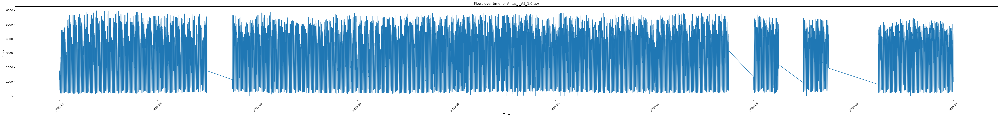

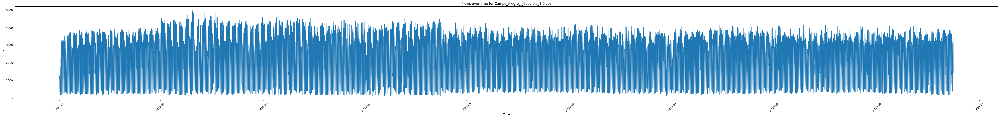

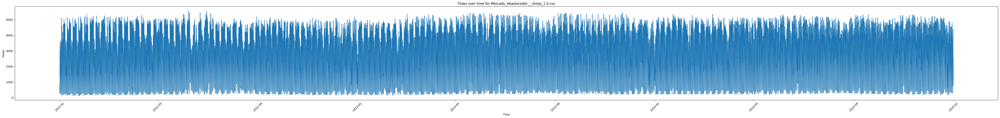

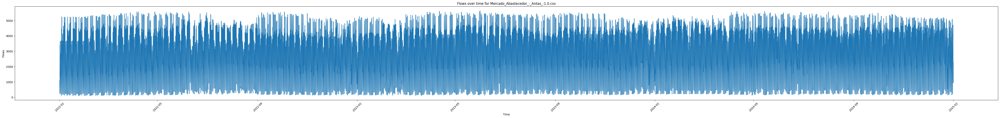

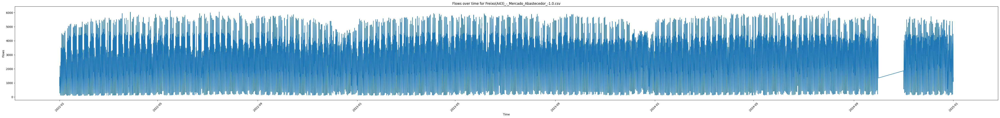

...

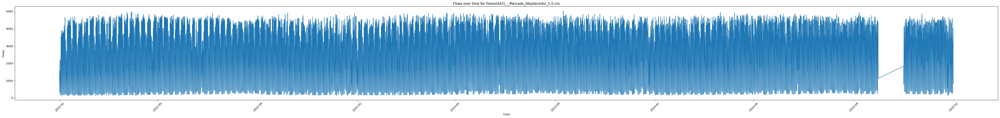

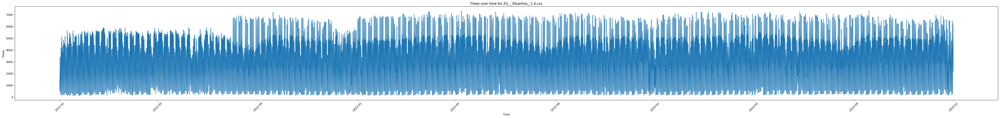

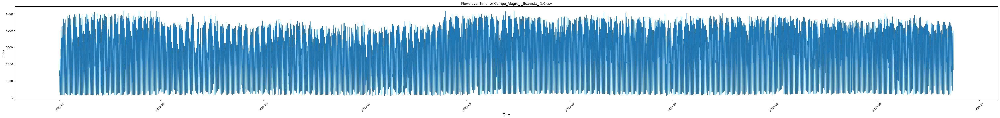

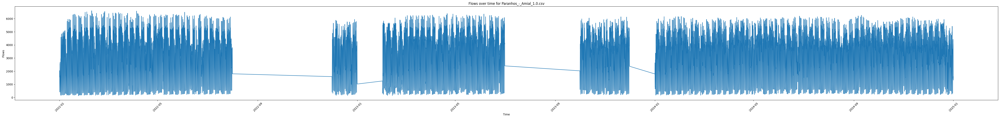

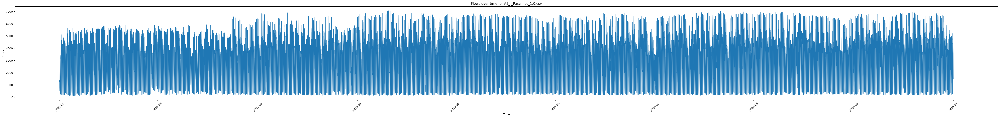

In [11]:
# load each one of the csv files and plot the flows for jan of 2024
import matplotlib.pyplot as plt
output_dir = "hourly_flows_by_detector"

for file in os.listdir(output_dir):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(output_dir, file), sep=';')
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        df = df.sort_values('timestamp')
        
        # df_2024 = df[df['timestamp'].dt.year == 2024]

        # # one month
        # df_2024_jan = df_2024[df_2024['timestamp'].dt.month == 1]
        # plt.figure(figsize=(12,6))
        # plt.plot(df_2024_jan['timestamp'], df_2024_jan['flows'])
        
        plt.figure(figsize=(50,6))
        plt.plot(df['timestamp'], df['flows'])
        
        plt.title(f"Flows over time for {file}")
        plt.xlabel("Time")
        plt.ylabel("Flows")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

        

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os

# full range
FULL_RANGE = pd.date_range(
    start="2022-01-01 00:00:00",
    end="2024-12-31 23:00:00",
    freq="h",
)
plots_dir = "missingDataHeatmap"
if not os.path.exists(plots_dir):
    os.makedirs(plots_dir)
    
for file in os.listdir(output_dir):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(output_dir, file), sep=';')
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        
        # reindex
        df = df.set_index('timestamp').reindex(FULL_RANGE).reset_index()
        df.rename(columns={'index': 'timestamp'}, inplace=True)

        df['date'] = df['timestamp'].dt.date
        df['hour'] = df['timestamp'].dt.hour
        pivot_df = df.pivot(index='hour', columns='date', values='flows')

        fig, ax = plt.subplots(figsize=(15, 6))
        
        # Plot heatmap
        sns.heatmap(pivot_df, 
                    cmap="viridis", 
                    ax=ax, 
                    cbar_kws={'label': 'Flow'},
                    xticklabels=False)
        
        ax.set_facecolor('white') # Gaps show as white


        unique_dates = pd.to_datetime(pivot_df.columns)
        month_starts = unique_dates[unique_dates.is_month_start]
        
        tick_indices = [pivot_df.columns.get_loc(d.date()) for d in month_starts]
        tick_labels = [d.strftime('%b %Y') for d in month_starts]

        ax.set_xticks(tick_indices)
        ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)

        plt.title(f"Hourly Flow Data Coverage: {file}", fontsize=14, pad=20)
        plt.xlabel("Month/Year")
        plt.ylabel("Hour of Day")
        
        plt.tight_layout()
        # plt.show()
        
        # Save
        save_name = file.replace('.csv', '_monthly_heatmap.png')
        plt.savefig(os.path.join(plots_dir, save_name), dpi=600)
        plt.close()

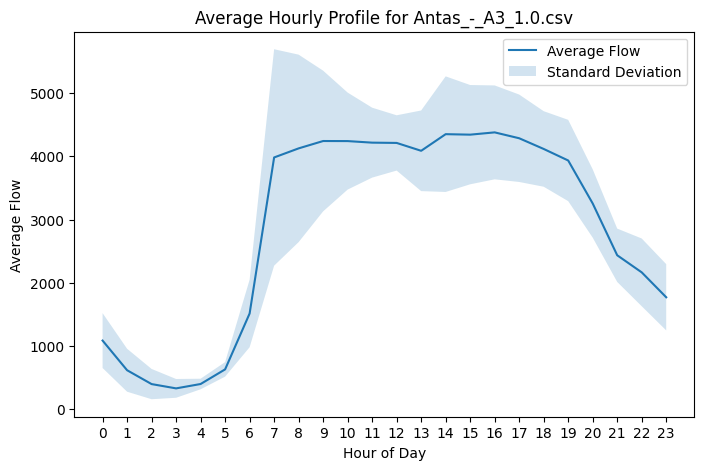

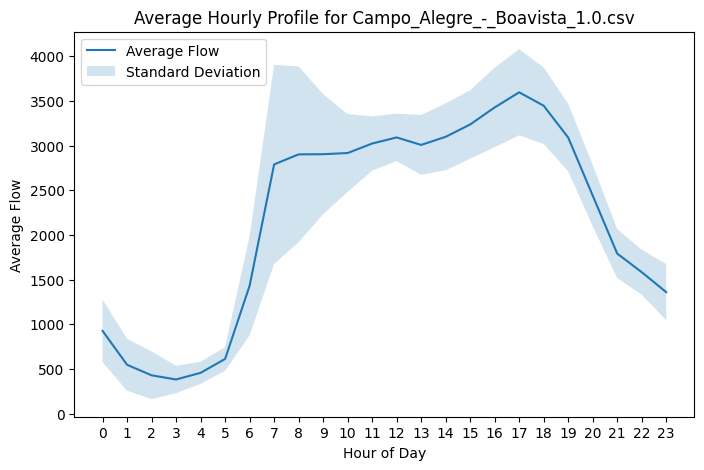

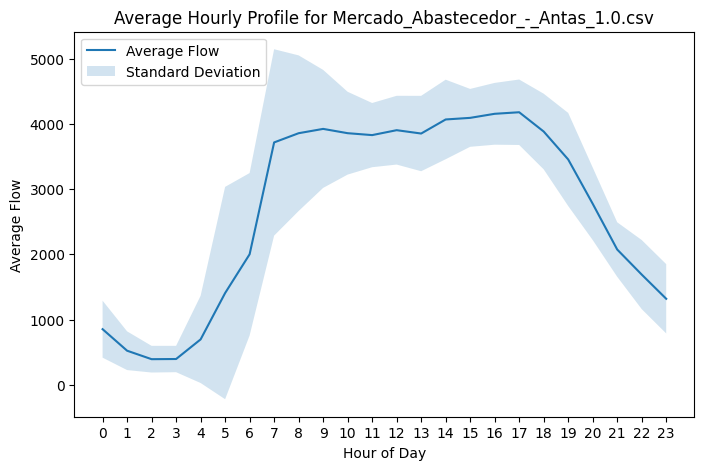

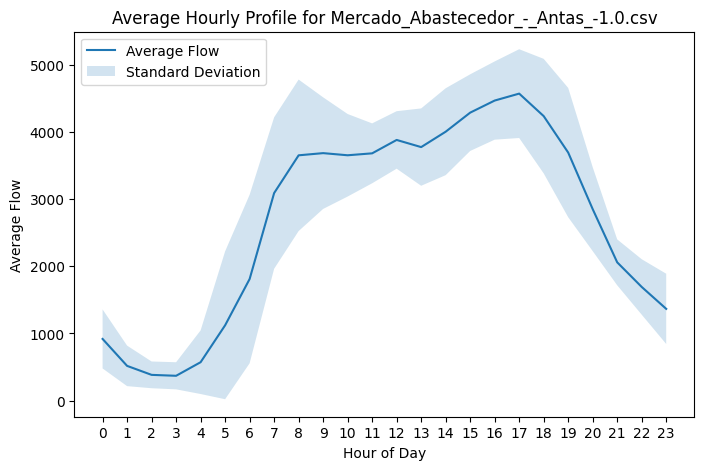

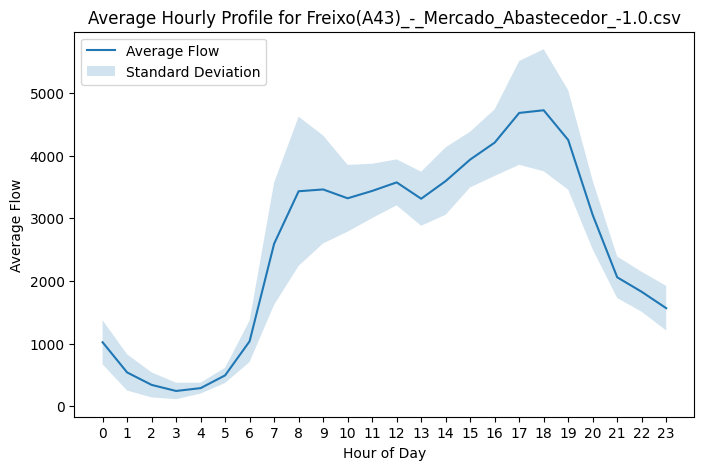

...

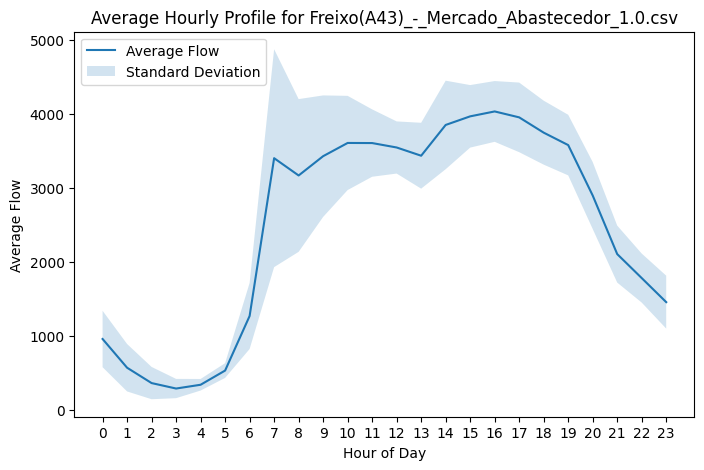

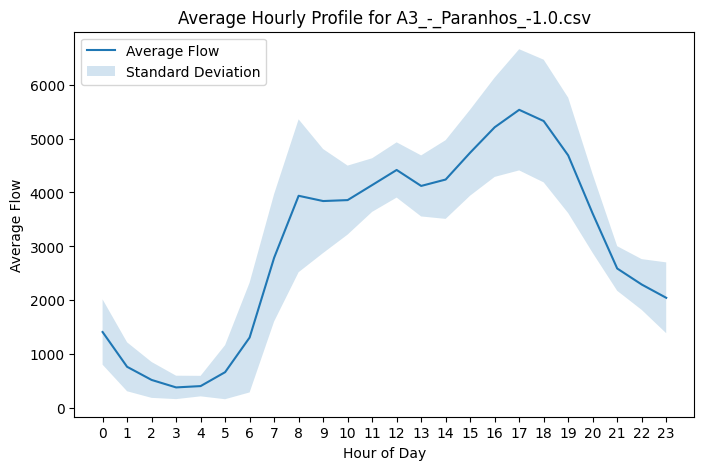

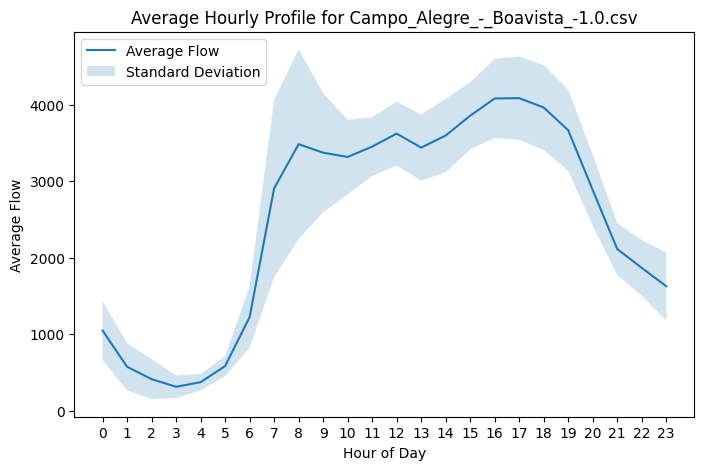

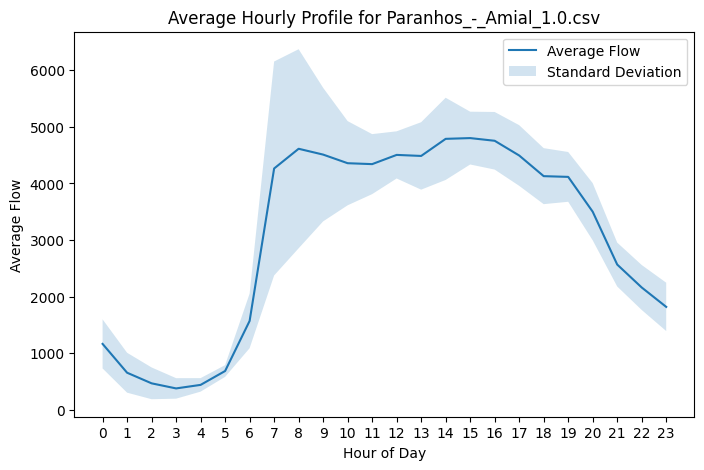

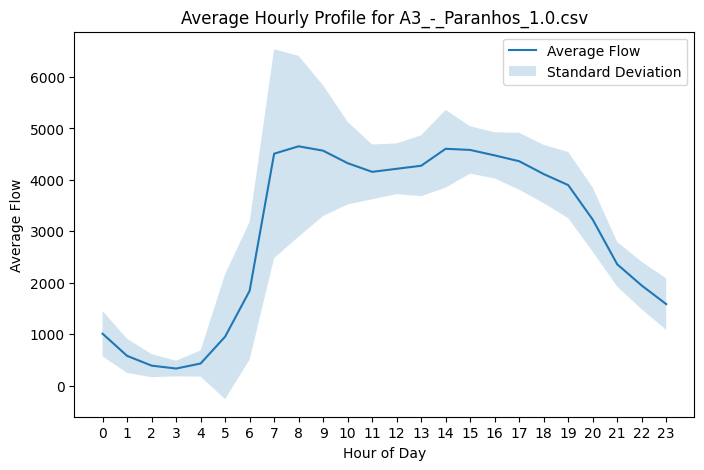

In [8]:
# load each one of the csv files and plot the average hourly profile (average flow per hour of day, averaged over all days) and standard deviation (as shaded area around the average) for the whole dataset

import matplotlib.pyplot as plt
for file in os.listdir(output_dir):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(output_dir, file), sep=';')
        df['timestamp'] = pd.to_datetime(df['timestamp'])

        df['hour'] = df['timestamp'].dt.hour
        hourly_avg = df.groupby('hour')['flows'].mean().reset_index()
        hourly_std = df.groupby('hour')['flows'].std().reset_index()

        plt.figure(figsize=(8,5))
        plt.plot(hourly_avg['hour'], hourly_avg['flows'])
        plt.fill_between(hourly_avg['hour'], 
                         hourly_avg['flows'] - hourly_std['flows'],
                         hourly_avg['flows'] + hourly_std['flows'],
                         alpha=0.2)
        plt.title(f"Average Hourly Profile for {file}")
        plt.xlabel("Hour of Day")
        plt.ylabel("Average Flow")
        plt.xticks(range(0,24))
        plt.legend(["Average Flow", "Standard Deviation"])
        plt.show()

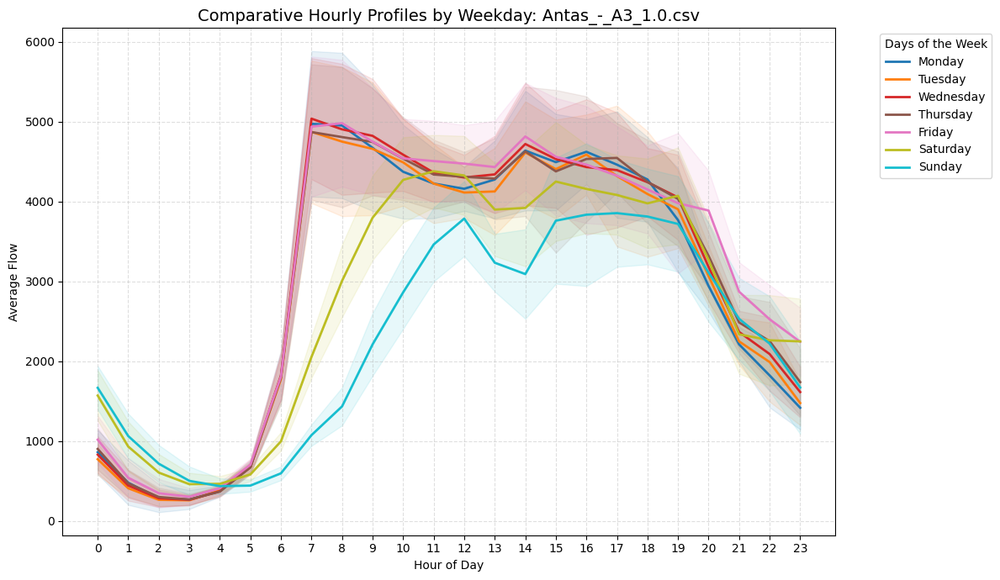

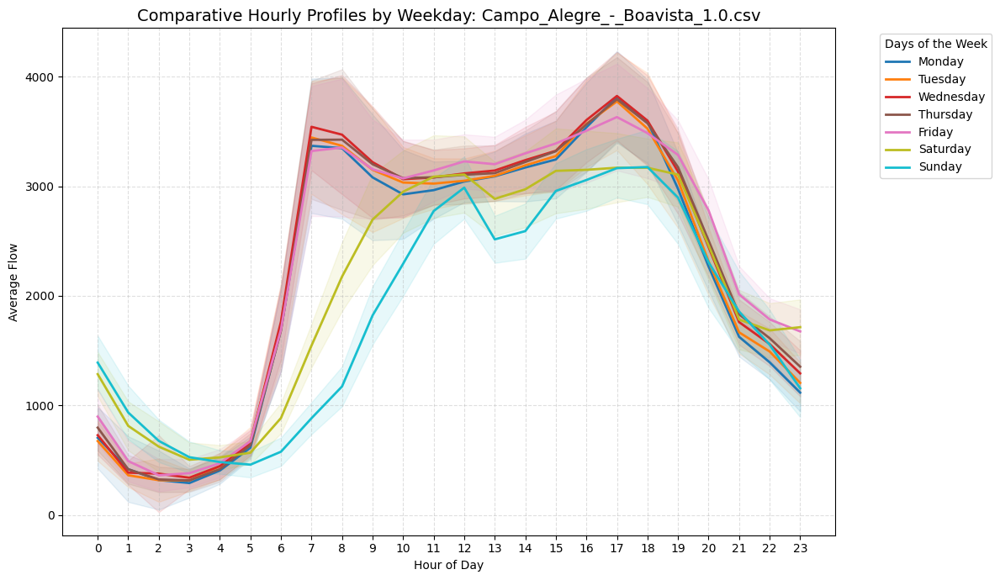

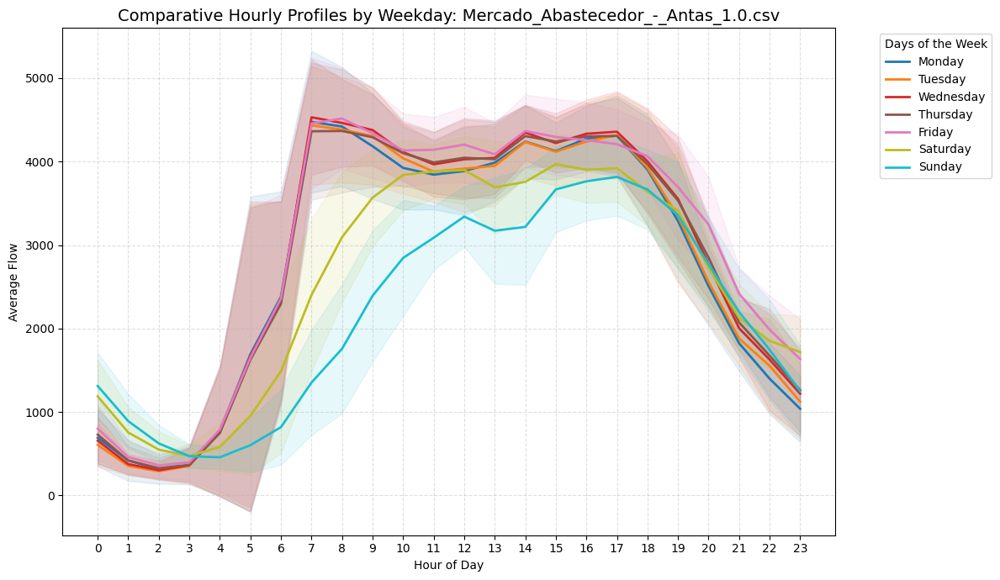

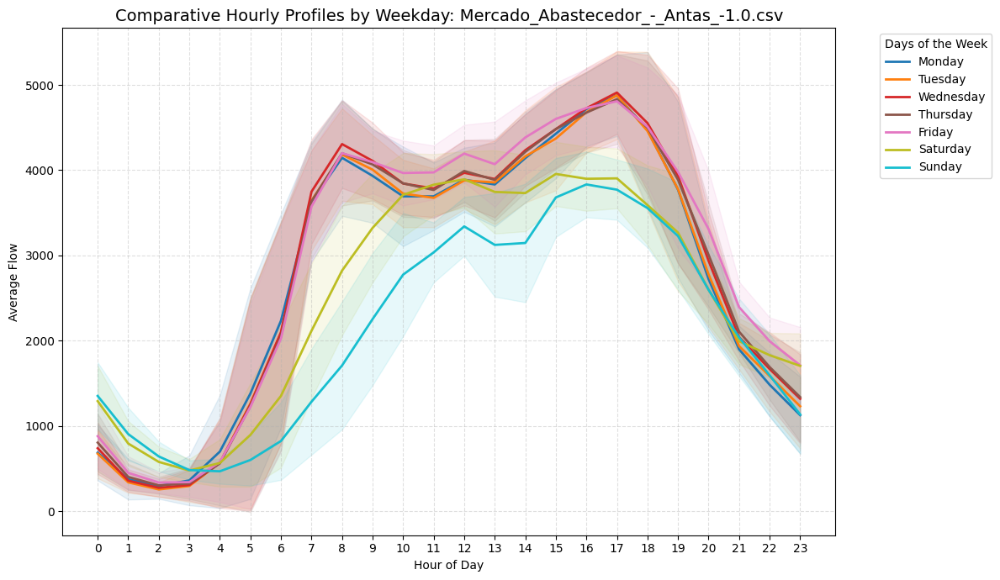

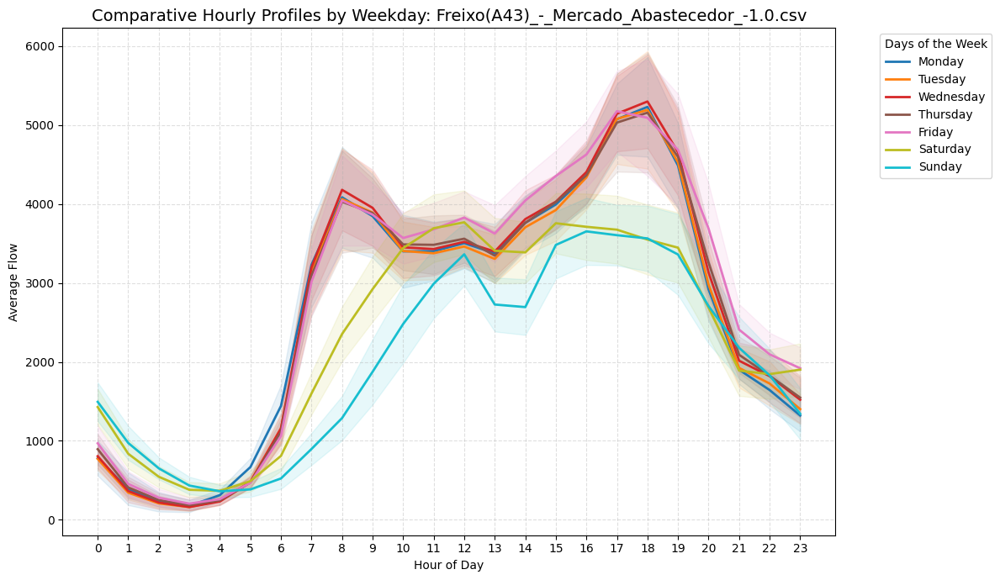

...

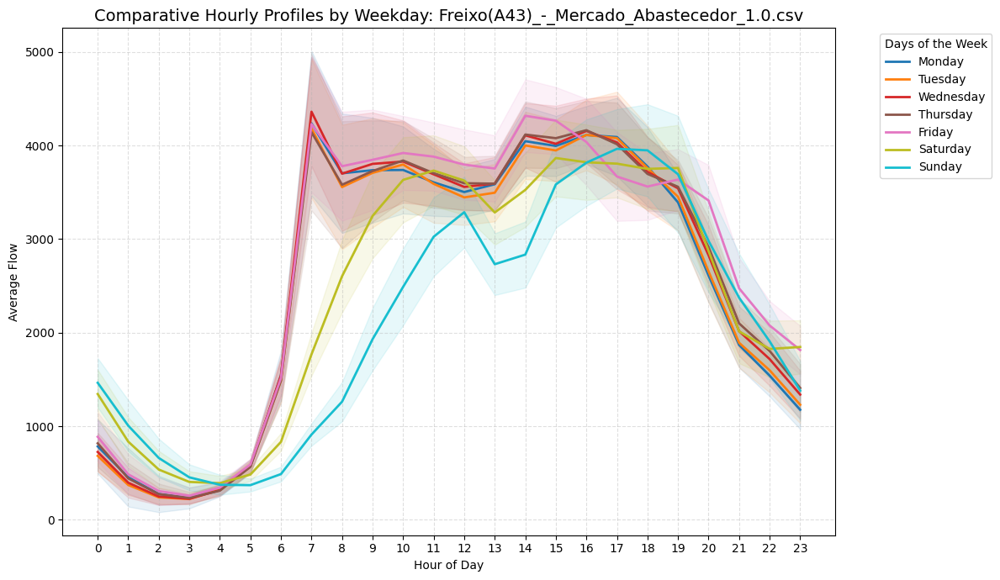

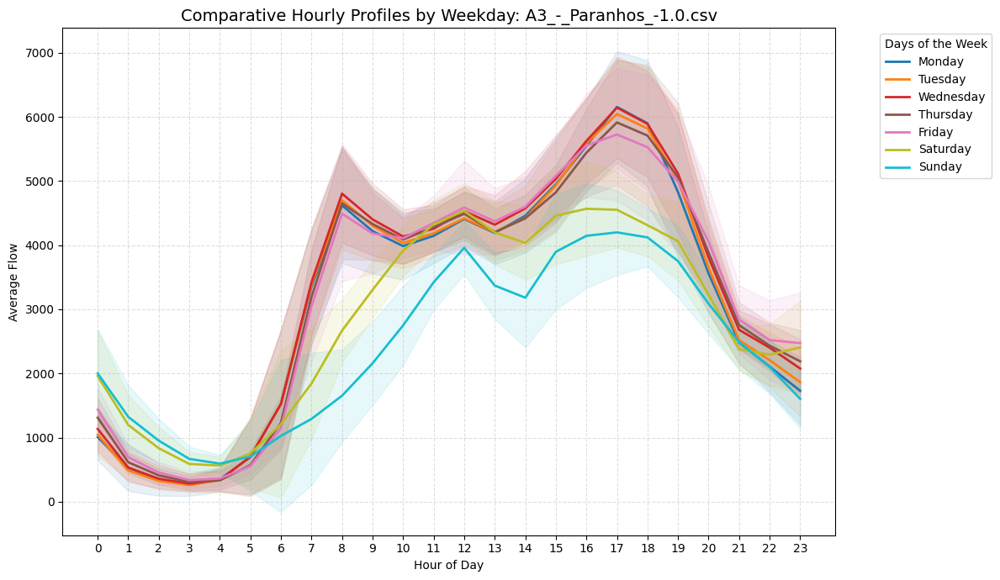

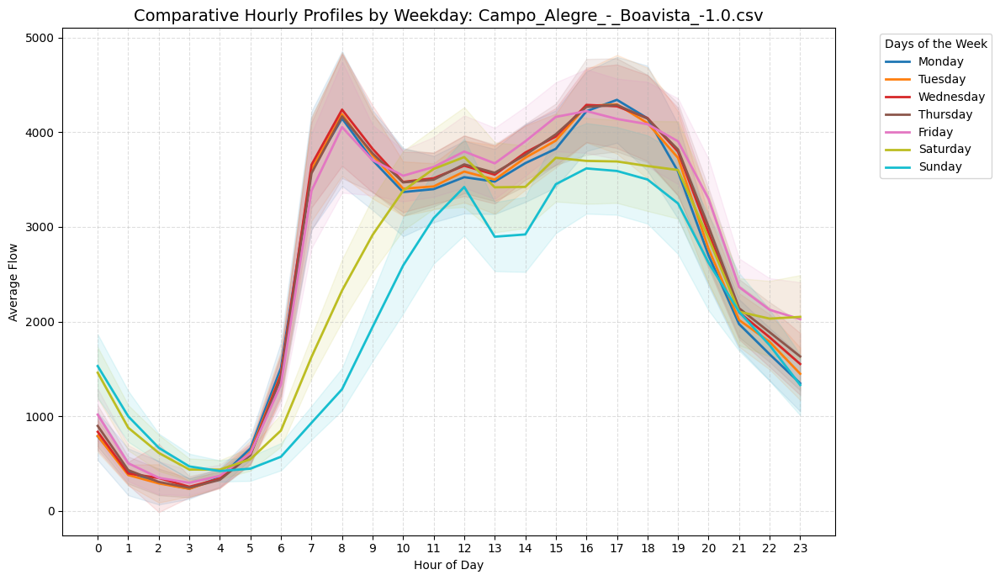

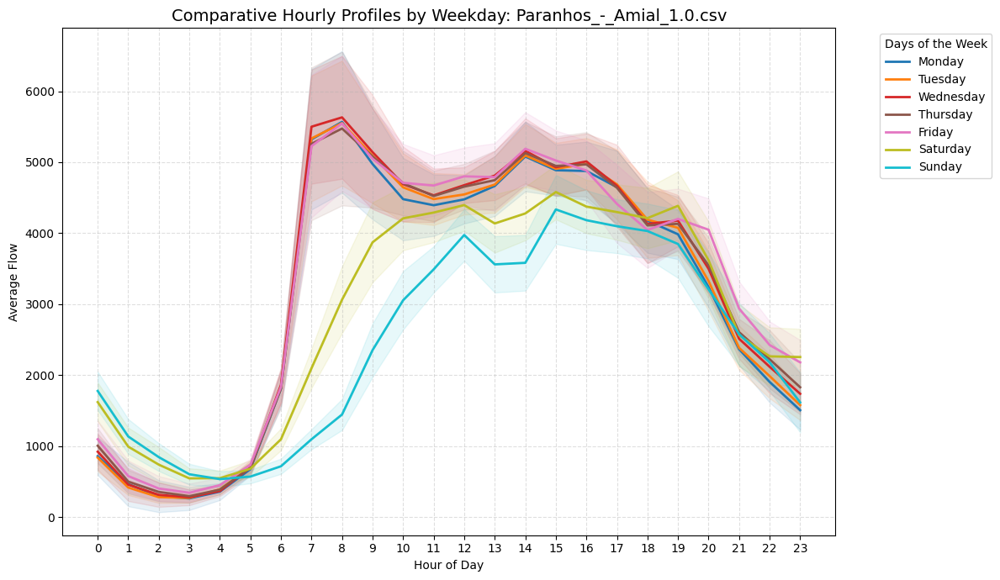

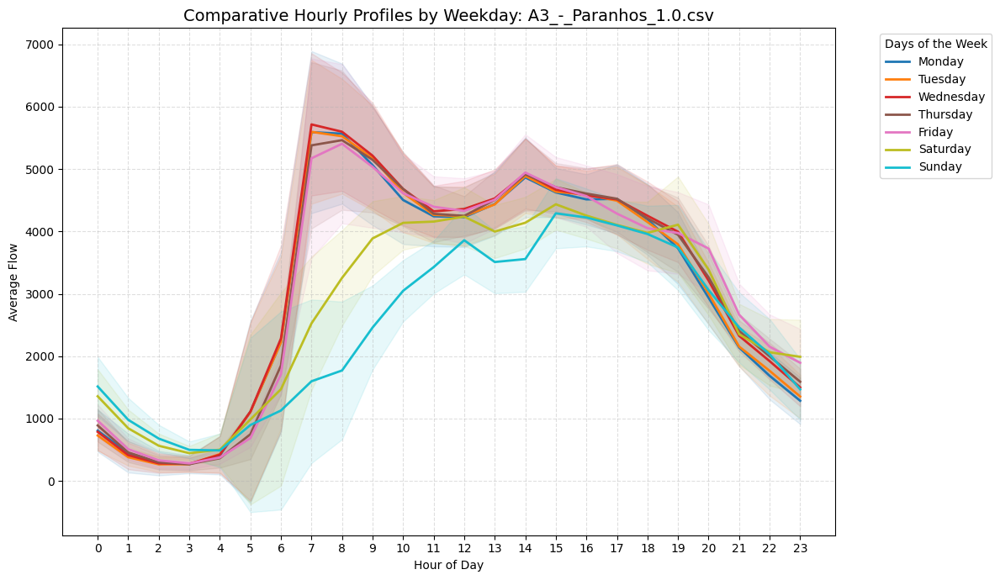

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os
output_dir = "hourly_flows_by_detector"


days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

colors = plt.get_cmap('tab10', 7)
plots_dir = "plots_output"
if not os.path.exists(plots_dir):
    os.makedirs(plots_dir)
    
for file in os.listdir(output_dir):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(output_dir, file), sep=';')
        df['timestamp'] = pd.to_datetime(df['timestamp'])

        df['hour'] = df['timestamp'].dt.hour
        df['day_name'] = df['timestamp'].dt.day_name()

        save_name = file.replace('.csv', '_hourly_profile.png')
        save_path = os.path.join(plots_dir, save_name)
        # Initialize the figure once per file
        plt.figure(figsize=(12, 7))
        
        for i, day in enumerate(days_order):
            # Filter for the specific day
            day_data = df[df['day_name'] == day]
            
            if day_data.empty:
                continue

            # Calculate stats for this specific day
            stats = day_data.groupby('hour')['flows'].agg(['mean', 'std']).reset_index()

            # Plot mean line
            plt.plot(stats['hour'], stats['mean'], label=day, color=colors(i), linewidth=2)
            
            # Add shaded standard deviation (alpha is kept low to avoid messy overlapping)
            plt.fill_between(stats['hour'], 
                             stats['mean'] - stats['std'],
                             stats['mean'] + stats['std'],
                             color=colors(i), alpha=0.1)

        # Formatting the single combined plot
        plt.title(f"Comparative Hourly Profiles by Weekday: {file}", fontsize=14)
        plt.xlabel("Hour of Day")
        plt.ylabel("Average Flow")
        plt.xticks(range(0, 24))
        plt.grid(True, linestyle='--', alpha=0.4)
        
        # Place legend outside the plot area so it doesn't cover data
        plt.legend(title="Days of the Week", bbox_to_anchor=(1.05, 1), loc='upper left')
        
        plt.tight_layout()
        
        plt.savefig(save_path, format="png", dpi=600)
        plt.show()

## Data Quality & Validation

### Missing Data

% missing hours per detector

Consecutive missing blocks

Seasonal missing patterns

Heatmap of missing timestamps

In [4]:
output_dir = "hourly_flows_by_detector"


Processing Antas_-_A3_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


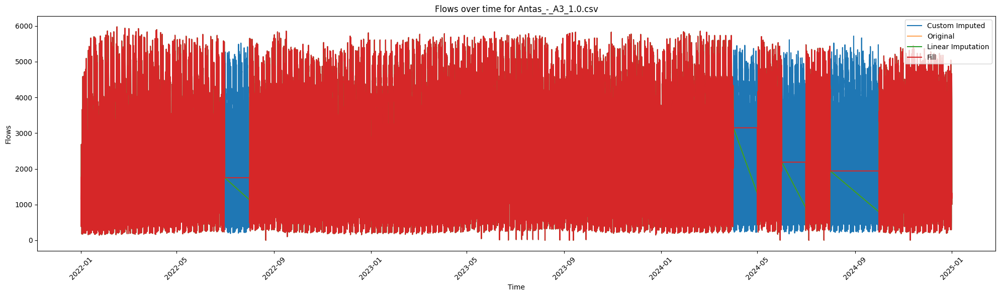


Processing Campo_Alegre_-_Boavista_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


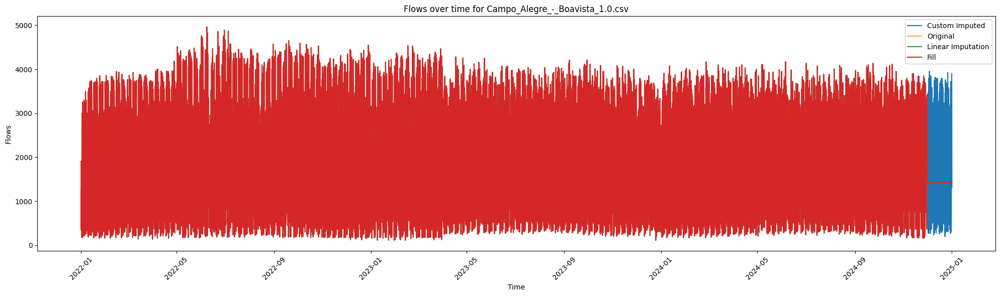


Processing Mercado_Abastecedor_-_Antas_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


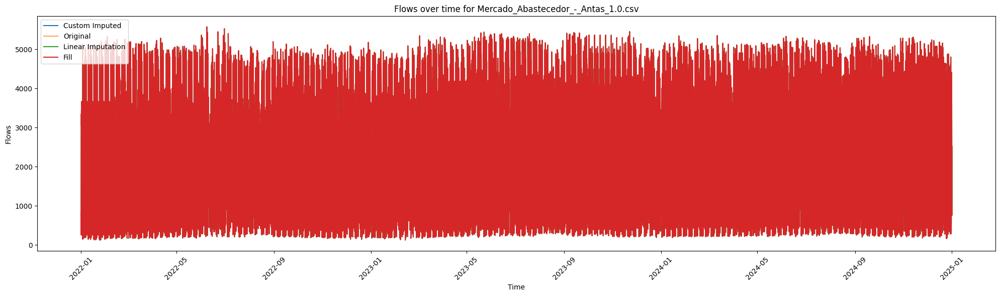


Processing Mercado_Abastecedor_-_Antas_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


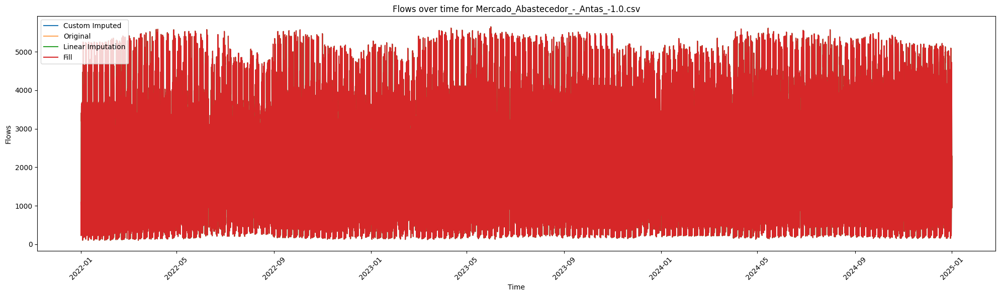


Processing Freixo(A43)_-_Mercado_Abastecedor_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


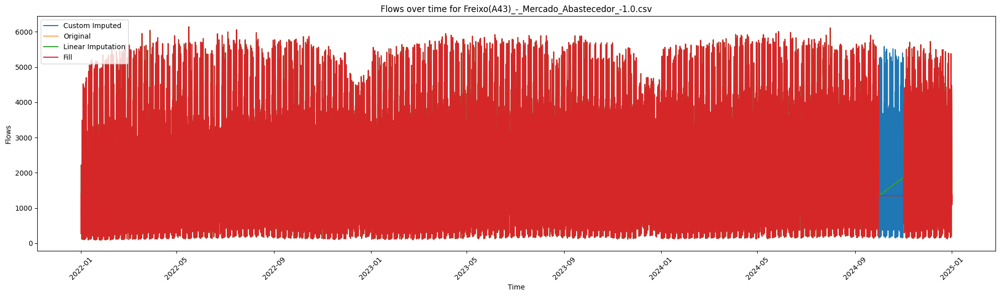


Processing Paranhos_-_Amial_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


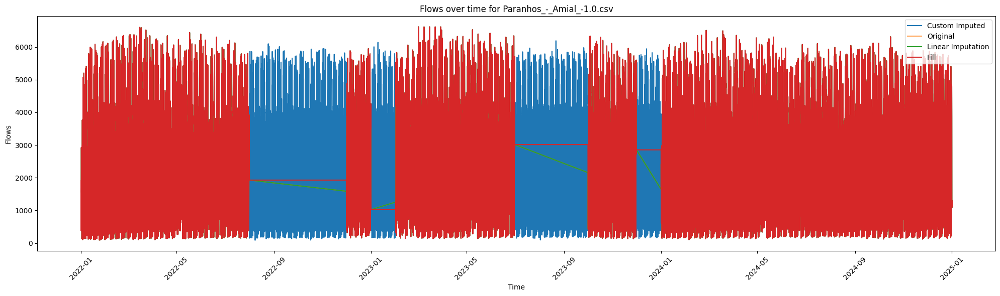


Processing Antas_-_A3_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


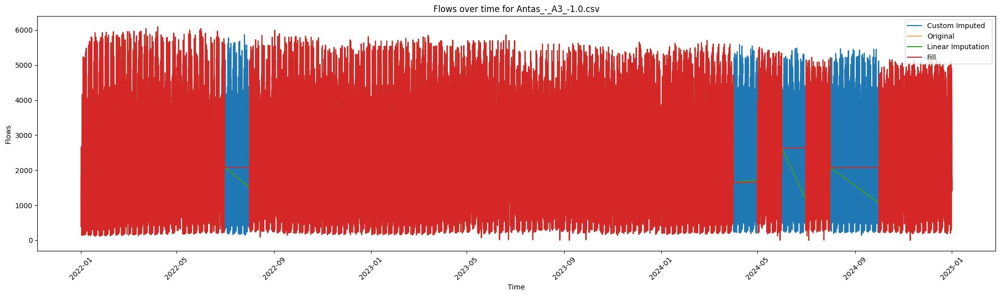


Processing Freixo(A43)_-_Mercado_Abastecedor_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


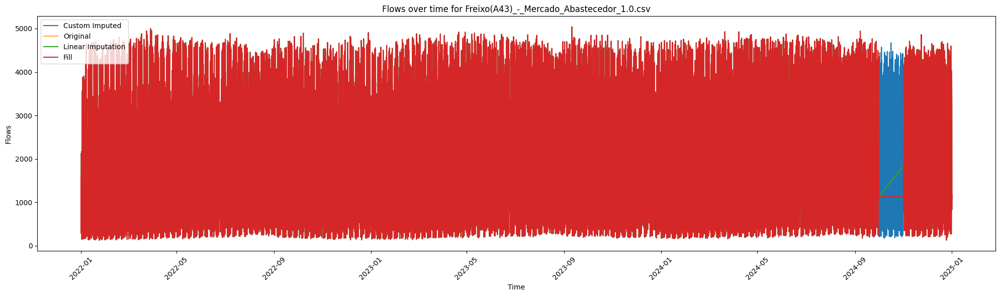


Processing A3_-_Paranhos_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


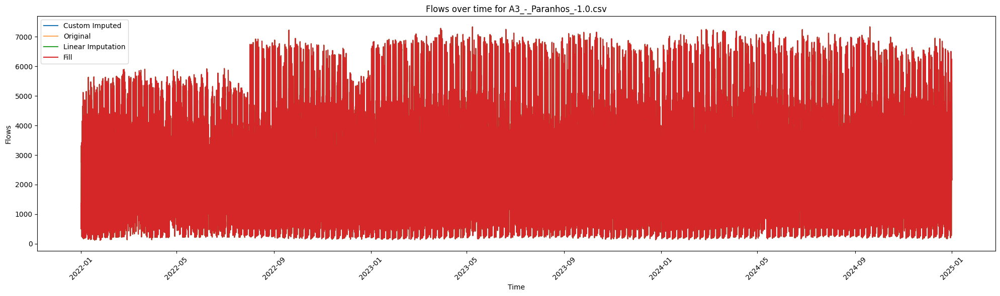


Processing Campo_Alegre_-_Boavista_-1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


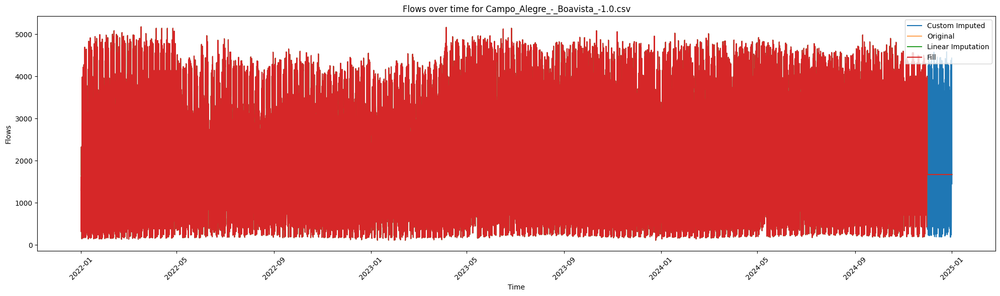


Processing Paranhos_-_Amial_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


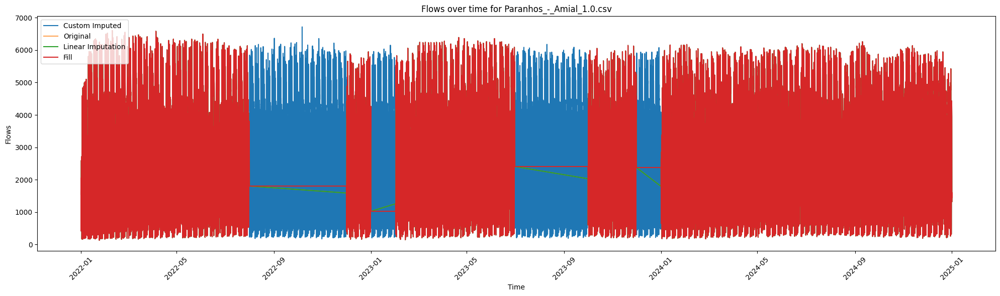


Processing A3_-_Paranhos_1.0.csv


/tmp/ipykernel_1391282/3377897430.py:11: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  return df.interpolate(method='time').bfill().ffill()


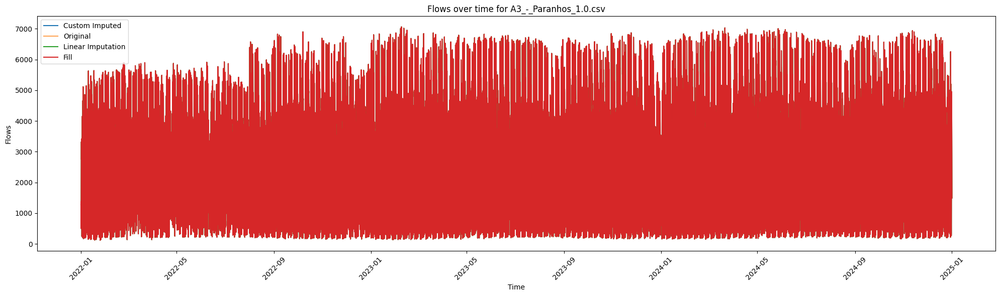

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from input import impute
from input2 import impute2

def impute_ffill(df):
    return df.ffill().bfill()

def impute_interpolate(df):
    return df.interpolate(method='time').bfill().ffill()

def evaluate_imputation(df_original, method_func, name):
    df = df_original.copy()

    # ---- simulate missing ----
    mask = df['flows'].notna()
    sample_idx = df[mask].sample(frac=0.05, random_state=42).index

    true_values = df.loc[sample_idx, 'flows'].copy()
    df.loc[sample_idx, 'flows'] = np.nan

    # ---- impute ----
    df_imputed = method_func(df)

    pred_values = df_imputed.loc[sample_idx, 'flows']

    # ---- metrics ----
    mae = np.mean(np.abs(true_values - pred_values))
    rmse = np.sqrt(np.mean((true_values - pred_values)**2))

    print(f"{name} -> MAE: {mae:.2f}, RMSE: {rmse:.2f}")

    return df_imputed, mae, rmse

for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue

    print(f"\nProcessing {file}")

    # ================= LOAD =================
    dfori = pd.read_csv(os.path.join(output_dir, file), sep=';')
    dfori['timestamp'] = pd.to_datetime(dfori['timestamp'])
    dfori = dfori.sort_values('timestamp').set_index('timestamp')

    full_range = pd.date_range(
        start="2022-01-01 00:00:00",
        end="2024-12-31 23:00:00",
        freq="h"
    )

    df = dfori.reindex(full_range)
    df.index.name = "timestamp"

    noiseFac = 0.3

    df_custom = impute(df, noiseFac) # hour + weekday
    df_custom2 = impute2(df, noiseFac) # hour

    # df_linear = impute_interpolate(df)
    # df_fill = impute_ffill(df)

    # missing_after = df['flows'].isna().sum()
    # print(f"Missing after: {missing_after*100/len(full_range):.2f}%")
    
    # Plot
    # plt.figure(figsize=(20,6))
    # plt.plot(df_custom.index, df_custom['flows'], label='Custom Imputed')
    # plt.plot(dfori.index, dfori['flows'], label='Original', alpha=0.7)
    # plt.plot(df_linear.index, df_linear['flows'], label='Linear Imputation')
    # plt.plot(df_fill.index, df_fill['flows'], label='Fill')
    # plt.title(f"Flows over time for {file}")
    # plt.xlabel("Time")
    # plt.ylabel("Flows")
    # plt.xticks(rotation=45)
    # plt.legend()
    # plt.tight_layout()
    # plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit

output_dir = "hourly_flows_by_detector"

train_ratio = 0.70
val_ratio = 0.15

# holidays
holidays_list = [
    dt.date(2022,1,1), dt.date(2022,3,1), dt.date(2022,4,15), dt.date(2022,4,17),
    dt.date(2022,4,25), dt.date(2022,5,1), dt.date(2022,6,10), dt.date(2022,6,16),
    dt.date(2022,6,24), dt.date(2022,8,15), dt.date(2022,10,5), dt.date(2022,11,1),
    dt.date(2022,12,1), dt.date(2022,12,8), dt.date(2022,12,25),

    dt.date(2023,1,1), dt.date(2023,2,21), dt.date(2023,4,7), dt.date(2023,4,9),
    dt.date(2023,4,25), dt.date(2023,5,1), dt.date(2023,6,10), dt.date(2023,6,8),
    dt.date(2023,6,24), dt.date(2023,8,15), dt.date(2023,10,5), dt.date(2023,11,1),
    dt.date(2023,12,1), dt.date(2023,12,8), dt.date(2023,12,25),

    dt.date(2024,1,1), dt.date(2024,2,13), dt.date(2024,3,29), dt.date(2024,3,31),
    dt.date(2024,4,25), dt.date(2024,5,1), dt.date(2024,6,10), dt.date(2024,5,30),
    dt.date(2024,6,24), dt.date(2024,8,15), dt.date(2024,10,5), dt.date(2024,11,1),
    dt.date(2024,12,1), dt.date(2024,12,8), dt.date(2024,12,25),
]

missing=[]
for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue

    print(f"\nProcessing {file}")

    # ================= LOAD =================
    dfori = pd.read_csv(os.path.join(output_dir, file), sep=';')
    dfori['timestamp'] = pd.to_datetime(dfori['timestamp'])
    dfori = dfori.sort_values('timestamp').set_index('timestamp')

    # ================= REINDEX =================
    full_range = pd.date_range(
        start="2022-01-01 00:00:00",
        end="2024-12-31 23:00:00",
        freq="h"
    )

    df = dfori.reindex(full_range)
    df.index.name = "timestamp"

    missing_before = df['flows'].isna().sum()
    print(f"Missing before: {missing_before*100/len(full_range):.2f}%")

    if missing_before == 0:
        missing.append(file)


Processing Antas_-_A3_1.0.csv
Missing before: 13.87%

Processing Campo_Alegre_-_Boavista_1.0.csv
Missing before: 2.83%

Processing Mercado_Abastecedor_-_Antas_1.0.csv
Missing before: 0.00%

Processing Mercado_Abastecedor_-_Antas_-1.0.csv
Missing before: 0.00%

Processing Freixo(A43)_-_Mercado_Abastecedor_-1.0.csv
Missing before: 2.83%

Processing Paranhos_-_Amial_-1.0.csv
Missing before: 25.18%

Processing Antas_-_A3_-1.0.csv
Missing before: 13.87%

Processing Freixo(A43)_-_Mercado_Abastecedor_1.0.csv
Missing before: 2.83%

Processing A3_-_Paranhos_-1.0.csv
Missing before: 0.00%

Processing Campo_Alegre_-_Boavista_-1.0.csv
Missing before: 2.83%

Processing Paranhos_-_Amial_1.0.csv
Missing before: 25.18%

Processing A3_-_Paranhos_1.0.csv
Missing before: 0.00%


In [3]:
missing

['Mercado_Abastecedor_-_Antas_1.0.csv',
 'Mercado_Abastecedor_-_Antas_-1.0.csv',
 'A3_-_Paranhos_-1.0.csv',
 'A3_-_Paranhos_1.0.csv']